# Survival Analysis

In [4]:
library(tidyverse)
suppressPackageStartupMessages(library(SummarizedExperiment))
suppressPackageStartupMessages(library(survival))
suppressPackageStartupMessages(library(survminer))

In [5]:
data_dir <- "~/dataset_1/database/UCSC_Xena/TCGA-COAD"

In [11]:
eSet <- readRDS(file.path(data_dir, "TCGA-COAD.star_counts.rds"))
eSet <- eSet[, eSet$Group == "Tumor"]
eSet

class: SummarizedExperiment 
dim: 21284 473 
metadata(0):
assays(2): counts TPM
rownames(21284): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): basepairs gene_name gene_type
colnames(473): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(13): Patient_ID Gender ... Vital_Status Group

In [12]:
survival_dat <- file.path(data_dir, "TCGA-COAD.survival.tsv.gz") |> 
    read.table(header = TRUE, sep = "\t") |>
    select(sample, Event = OS, Time = OS.time)

head(survival_dat)

,sample,Event,Time
,<chr>,<int>,<dbl>
1,TCGA-AA-3492-11A,1,1
2,TCGA-AA-3492-01A,1,1
3,TCGA-AA-3525-11A,0,1
4,TCGA-AA-3525-01A,0,1
5,TCGA-G4-6626-01A,1,1
6,TCGA-AY-6196-01A,0,6


In [13]:
clinical_dat <- colData(eSet) |> 
    as.data.frame() |> 
    select("AJCC_Stage", "AJCC_T", "AJCC_N", "AJCC_M") |> 
    rownames_to_column(var = "sample") |>
    left_join(survival_dat, by = "sample") |>
    column_to_rownames(var = "sample") |>
    filter(Time > 30 & !is.na(Time) & !is.na(Event)) |>
    mutate(Time = Time / 30)

dim(clinical_dat)
head(clinical_dat)

[1] 436   6

,AJCC_Stage,AJCC_T,AJCC_N,AJCC_M,Event,Time
,<ord>,<ord>,<ord>,<ord>,<int>,<dbl>
TCGA-5M-AAT6-01A,Stage IV,T4,N2,M1,1,9.666667
TCGA-AA-3552-01A,Stage III,T3,N2,M0,1,13.200000
TCGA-AA-3867-01A,Stage IV,T3,N2,M1,0,24.366667
TCGA-AD-6895-01A,Stage III,T3,N1,M0,0,25.433333
TCGA-AA-3560-01A,Stage III,T3,N2,M0,0,20.266667
TCGA-CM-6676-01A,Stage I,T2,N0,M0,0,11.233333


In [14]:
norm_mat <- assay(eSet, "TPM")
norm_mat <- norm_mat[, rownames(clinical_dat)]

dim(norm_mat)

[1] 21284   436

In [ ]:
sfit <- survfit(
    Surv(Time, Event) ~ AJCC_Stage, data = clinical_dat)
print(sfit)

Call: survfit(formula = Surv(Time, Event) ~ AJCC_Stage, data = clinical_dat)

   11 observations deleted due to missingness 
                       n events median 0.95LCL 0.95UCL
AJCC_Stage=Stage I    73      3     NA    49.8      NA
AJCC_Stage=Stage II  166     23  101.4    82.5      NA
AJCC_Stage=Stage III 125     30     NA    55.4      NA
AJCC_Stage=Stage IV   61     31   28.6    16.8      NA


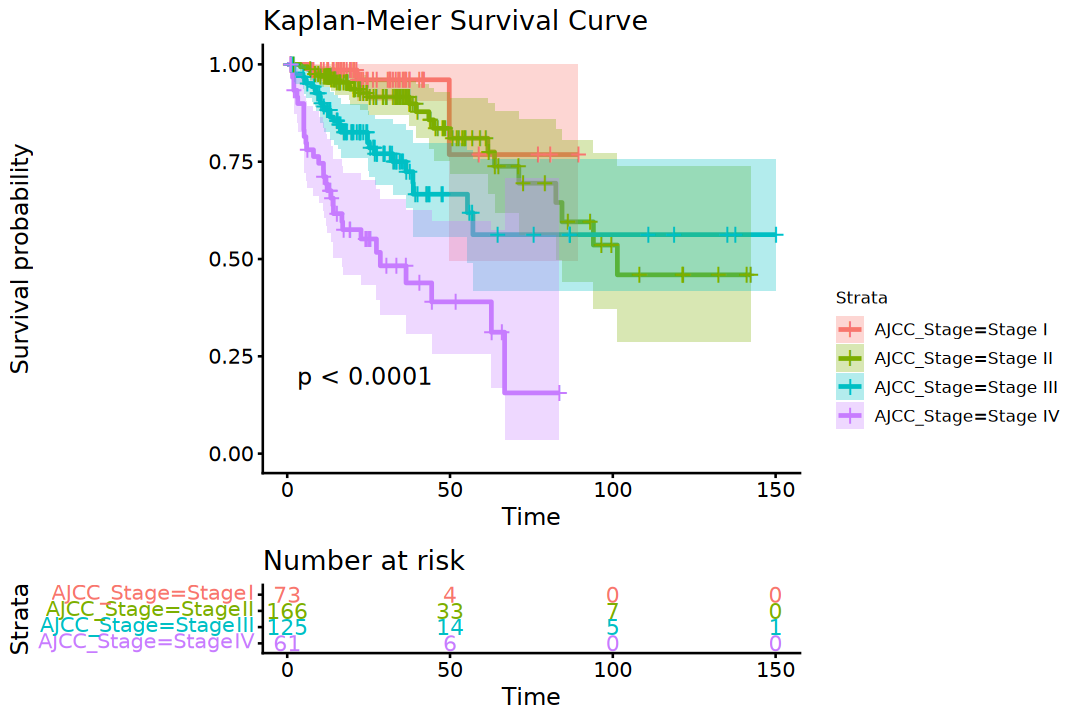

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggsurvplot(
    sfit, pval = TRUE, conf.int = TRUE,
    title = "Kaplan-Meier Survival Curve", legend = "right",
    risk.table = TRUE, risk.table.col = "strata")

In [17]:
logrank_test <- survdiff(
    Surv(Time, Event) ~ AJCC_Stage, data = clinical_dat)
print(logrank_test)

Call:
survdiff(formula = Surv(Time, Event) ~ AJCC_Stage, data = clinical_dat)

n=425, 11 observations deleted due to missingness.

                       N Observed Expected (O-E)^2/E (O-E)^2/V
AJCC_Stage=Stage I    73        3    13.14     7.829      9.39
AJCC_Stage=Stage II  166       23    39.32     6.773     12.60
AJCC_Stage=Stage III 125       30    25.19     0.919      1.30
AJCC_Stage=Stage IV   61       31     9.35    50.147     56.71

 Chisq= 66.1  on 3 degrees of freedom, p= 3e-14 


Call:
coxph(formula = Surv(Time, Event) ~ AJCC_Stage, data = clinical_dat)

  n= 425, number of events= 87 
   (11 observations deleted due to missingness)

                coef exp(coef) se(coef)     z Pr(>|z|)    
AJCC_Stage.L 1.96112   7.10726  0.41063 4.776 1.79e-06 ***
AJCC_Stage.Q 0.06094   1.06284  0.33516 0.182    0.856    
AJCC_Stage.C 0.12000   1.12749  0.23054 0.520    0.603    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

             exp(coef) exp(-coef) lower .95 upper .95
AJCC_Stage.L     7.107     0.1407    3.1782    15.894
AJCC_Stage.Q     1.063     0.9409    0.5510     2.050
AJCC_Stage.C     1.127     0.8869    0.7176     1.772

Concordance= 0.742  (se = 0.027 )
Likelihood ratio test= 51.74  on 3 df,   p=3e-11
Wald test            = 51.25  on 3 df,   p=4e-11
Score (logrank) test = 66.18  on 3 df,   p=3e-14


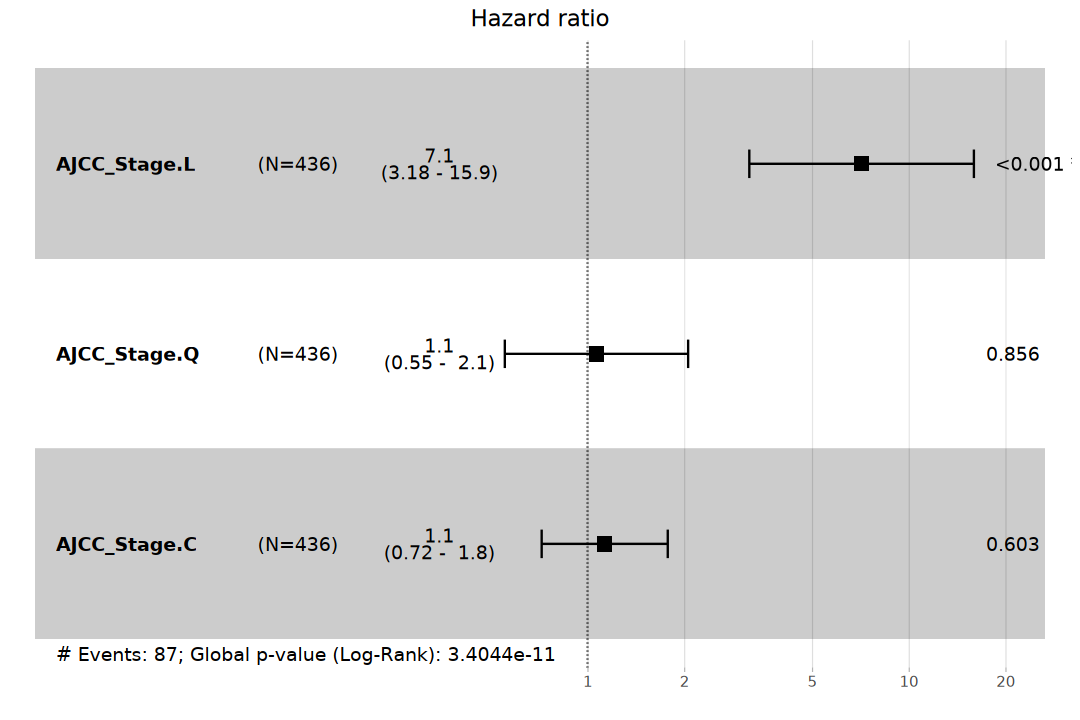

In [18]:
cox_model <- coxph(
    Surv(Time, Event) ~ AJCC_Stage, data = clinical_dat)

summary(cox_model)
ggforest(cox_model, data = clinical_dat, fontsize = 1)

In [19]:
targetGenes <- c("APC", "TP53", "KRAS", "SUGCT", "AURKA", "SKA3", "INHBB")

In [20]:
dat <- norm_mat[rownames(eSet)[rowData(eSet)$gene_name %in% targetGenes], ] |>
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "TPM") |>
    left_join(
        rowData(eSet) |> as.data.frame() |> 
            rownames_to_column("gene_id"),
        by = "gene_id")
head(dat)

gene_id,sample,TPM,basepairs,gene_name,gene_type
<chr>,<chr>,<dbl>,<int>,<chr>,<chr>
ENSG00000087586.18,TCGA-5M-AAT6-01A,44.59912,2928,AURKA,protein_coding
ENSG00000087586.18,TCGA-AA-3552-01A,44.84975,2928,AURKA,protein_coding
ENSG00000087586.18,TCGA-AA-3867-01A,60.90111,2928,AURKA,protein_coding
ENSG00000087586.18,TCGA-AD-6895-01A,56.90142,2928,AURKA,protein_coding
ENSG00000087586.18,TCGA-AA-3560-01A,47.22226,2928,AURKA,protein_coding
ENSG00000087586.18,TCGA-CM-6676-01A,101.64983,2928,AURKA,protein_coding


In [22]:
# remotes::install_github('erocoar/gghalves')
suppressPackageStartupMessages(library(gghalves))

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(dat, aes(x = gene_name, y = TPM, fill = gene_name, color = gene_name)) +
    geom_half_violin(color = "black", side = "top") +
    geom_boxplot(
        color = "black", width = 0.1, staplewidth = 0.4, outliers = FALSE,
        position = position_nudge(x = -0.1)) +
    geom_half_point(
        range_scale = 0.3, position = position_nudge(x = -0.5)) +
    # coord_flip(clip = "off") + 
    theme_classic() +
    theme(
        plot.margin = unit(c(0.5, 0.5, 0.5, 0.5), units = "cm"),
        panel.background = element_blank(),
        plot.background = element_blank(),
        axis.text = element_text(size = 16, color = "black"),
        axis.title = element_text(size = 18, color = "black"),
        legend.position = "none")

ERROR while rich displaying an object: Error in `geom_half_point()`:
! Problem while converting geom to grob.
ℹ Error occurred in the 3rd layer.
Caused by error in `fun()`:
! argument "layout" is missing, with no default

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[m

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
splots <- lapply(targetGenes, function(g) {
    quantiles <- quantile(exprMat[g, ])
    clinical_dat$Gene <- ifelse(exprMat[g, ] > quantiles[4], 'high', 'low')
    sfit <- survfit(Surv(Time, Event) ~ Gene, data = clinical_dat)
    ggsurvplot(sfit, pval = TRUE, data = clinical_dat, title = g)
})
arrange_ggsurvplots(splots, print = TRUE,  ncol = 3, nrow = 3)

In [ ]:
boxplot(expr_diseased, expr_healthy,
        names=c("Diseased", "Healthy"), main="Distribution of gene expression")

In [ ]:
ggsurvplot(sfit, palette = "jco", risk.table = TRUE, pval = TRUE, conf.int = TRUE)

In [ ]:
exp_s <- function(exprSet,meta,color = c("#2874C5", "#f87669")){
  splots <- lapply(gs, function(g){
    i = which(gs== g)
    meta$gene=ifelse(as.numeric(exprSet[g,]) > median(as.numeric(exprSet[g,])),'high','low')
    if(length(unique(meta$gene))==1) stop(paste0("gene",g,"with too low expression"))
    sfit1=survival::survfit(survival::Surv(time, event)~gene, data=meta)
    p = survminer::ggsurvplot(sfit1,pval =TRUE,
                              palette = rev(color),
                              data = meta,
                              legend = c(0.8,0.8),
                              title = gs[[i]],
                              legend.title='Expression',
                              xlab="Time_month",
                              surv.median.line = 'hv',
                              risk.table = T,
                              risk.table.pos=c('in'),
                              ggtheme = theme_bw(base_size = 12)
    )
    p2 = p$plot+
      theme(plot.title = element_text(hjust = 0.5))
    return(p2)
  })
  return(splots)
}

t = exp_s(exprSet,meta)
patchwork::wrap_plots(t)